# Data exploration: what predicts a union election win?


Our target `union_won` is 0/1, so next to the lecture plots I use one more: the **win rate per
group**, the mean of `union_won` within each bin or category. It answers "does this feature move
the odds?" directly, so the explanatory figures use it.

**Contents**
1. Setup and a first look
2. The target
3. One column at a time
4. Each feature vs. the target
5. Pairs of features
6. Ranking: which features matter most?
7. Closer look: days from petition to election
8. Candidate explanatory figures for the report
9. Recommendations and to-dos

**Short version** (details in sections 6 to 9; the numbers are printed in the cells below):
- Unions win **70.8%** of the 15,270 elections.
- **Days to election** has a clear pattern: **86%** of elections held within 2 weeks of the
  petition are won, but only **44%** of those held more than a year after it. Faster elections
  win more **under every set of NLRB rules**, for every unit size, and whether or not the employer
  has a lawyer, so it's not just a stand-in for one of those.
- The NLRB's own rule changes (2015, 2020, 2023) moved the median wait between **23 and 38 days**
  almost overnight. This is the most interesting story in the data.
- Other strong signals: **unit size** (small units win more), **employer has a lawyer**
  (85% → 69%), **parent union** (48% to 89%), and **year** (win rate up from 63% to 77%).
- Weak or no signal: petitioner's lawyer, election month, census region.
- Recommended report figures: see section 9.

# Setup

In [31]:
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pylab as plt

pd.set_option('display.width', 200)

# same look for every figure: no top/right border, light grid behind the data
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#e6e6e6'
plt.rcParams['axes.axisbelow'] = True

BLUE = '#2a78d6'        # main color
LIGHT_BLUE = '#86b6ef'  # lighter step of the same blue, for ordered pairs (e.g. faster / slower)
ORANGE = '#eb6834'      # contrast color (e.g. won vs lost)
GRAY = '#9a9a9a'        # reference lines and context

df = pd.read_csv('../data/elections_clean.csv', parse_dates=['file_date', 'election_date', 'petition_date'])
print(df.shape)
print(df.dtypes)

(15270, 23)
fiscal_year                           int64
case_number                             str
case_type                               str
case_name                               str
employer                                str
city                                    str
state                                   str
census_region                           str
union_name                              str
parent_union                            str
eligible                            float64
file_date                    datetime64[us]
election_date                datetime64[us]
n_participants                      float64
employer_has_lawyer                 float64
n_employer_lawyers                  float64
employer_law_firms                      str
petitioner_has_lawyer               float64
n_petitioner_lawyers                float64
has_intervenor                      float64
petition_date                datetime64[us]
days_petition_to_election           float64
union_won           

## Exploration 1 
Using a Heatmap to find correlations between pairs of features

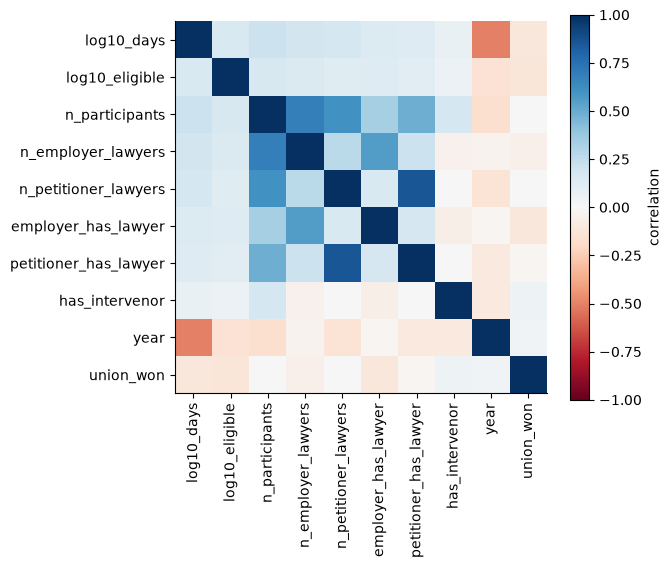

In [32]:
df['year'] = df['file_date'].dt.year
df['log10_days'] = np.log10(df['days_petition_to_election'])
df['log10_eligible'] = np.log10(df['eligible'])

numeric_cols = ['log10_days', 'log10_eligible', 'n_participants', 'n_employer_lawyers', 'n_petitioner_lawyers',
                'employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor', 'year', 'union_won']
corr = df[numeric_cols].corr()

plt.figure(figsize=(6,5))
plt.imshow(corr, cmap='RdBu', vmin=-1, vmax=1)   # blue = positive, red = negative, white = 0
plt.colorbar(label='correlation')
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=90)
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.grid(False)
plt.show()




## Exploration 2

From the heatmap it makes most sense to see which lawyer feature has the most impact 

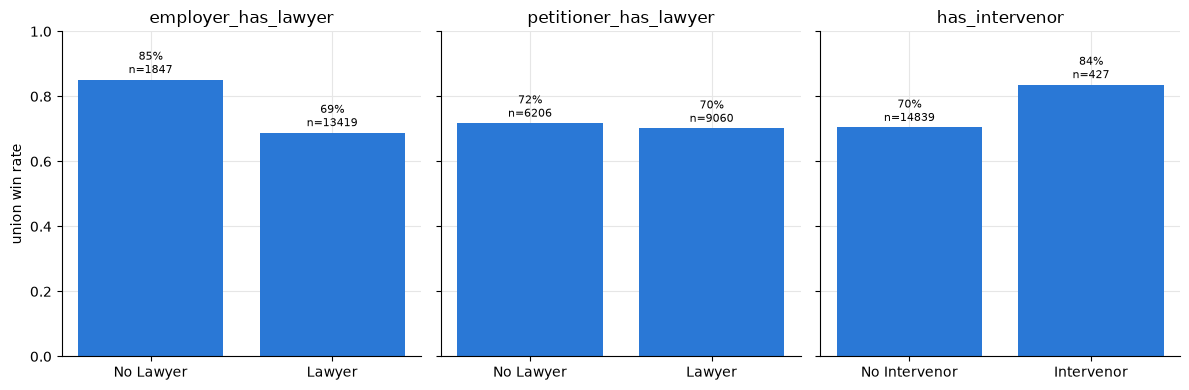

In [33]:
lawyer_cols = ['employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor']

fig, axes = plt.subplots(1, len(lawyer_cols), figsize=(12, 4), sharey=True)

g = df.groupby('employer_has_lawyer')['union_won'].agg(['mean', 'size'])
axes[0].bar(g.index.map({0.0: 'No Lawyer', 1.0: 'Lawyer'}), g['mean'], color=BLUE)

axes[0].set_title('employer_has_lawyer')
axes[0].set_ylim(0, 1)
    
for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
    axes[0].text(i, m + 0.02, f'{m:.0%}\nn={n}', ha='center', fontsize=8)

g = df.groupby('petitioner_has_lawyer')['union_won'].agg(['mean', 'size'])
axes[1].bar(g.index.map({0.0: 'No Lawyer', 1.0: 'Lawyer'}), g['mean'], color=BLUE)

axes[1].set_title('petitioner_has_lawyer')
axes[1].set_ylim(0, 1)
    
for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
    axes[1].text(i, m + 0.02, f'{m:.0%}\nn={n}', ha='center', fontsize=8)


g = df.groupby('has_intervenor')['union_won'].agg(['mean', 'size'])
axes[2].bar(g.index.map({0.0: 'No Intervenor', 1.0: 'Intervenor'}), g['mean'], color=BLUE)

axes[2].set_title('has_intervenor')
axes[2].set_ylim(0, 1)
    
for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
    axes[2].text(i, m + 0.02, f'{m:.0%}\nn={n}', ha='center', fontsize=8)


axes[0].set_ylabel('union win rate')
plt.tight_layout()
plt.show()
fig.savefig("../figures/sydney_eda/figure_1.png", dpi=300, bbox_inches="tight")


## Exploration 3

For this exploration we decided to look at the regions/where and if that had any impact

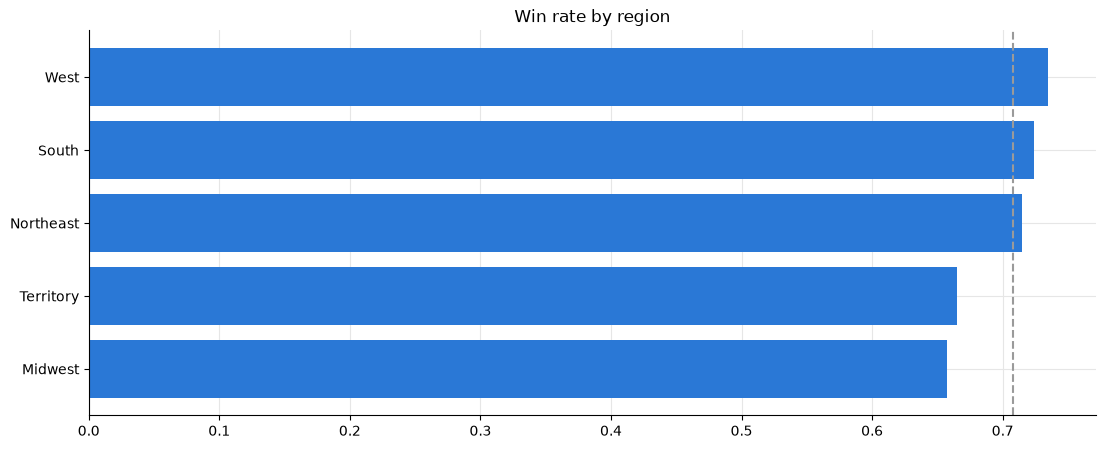

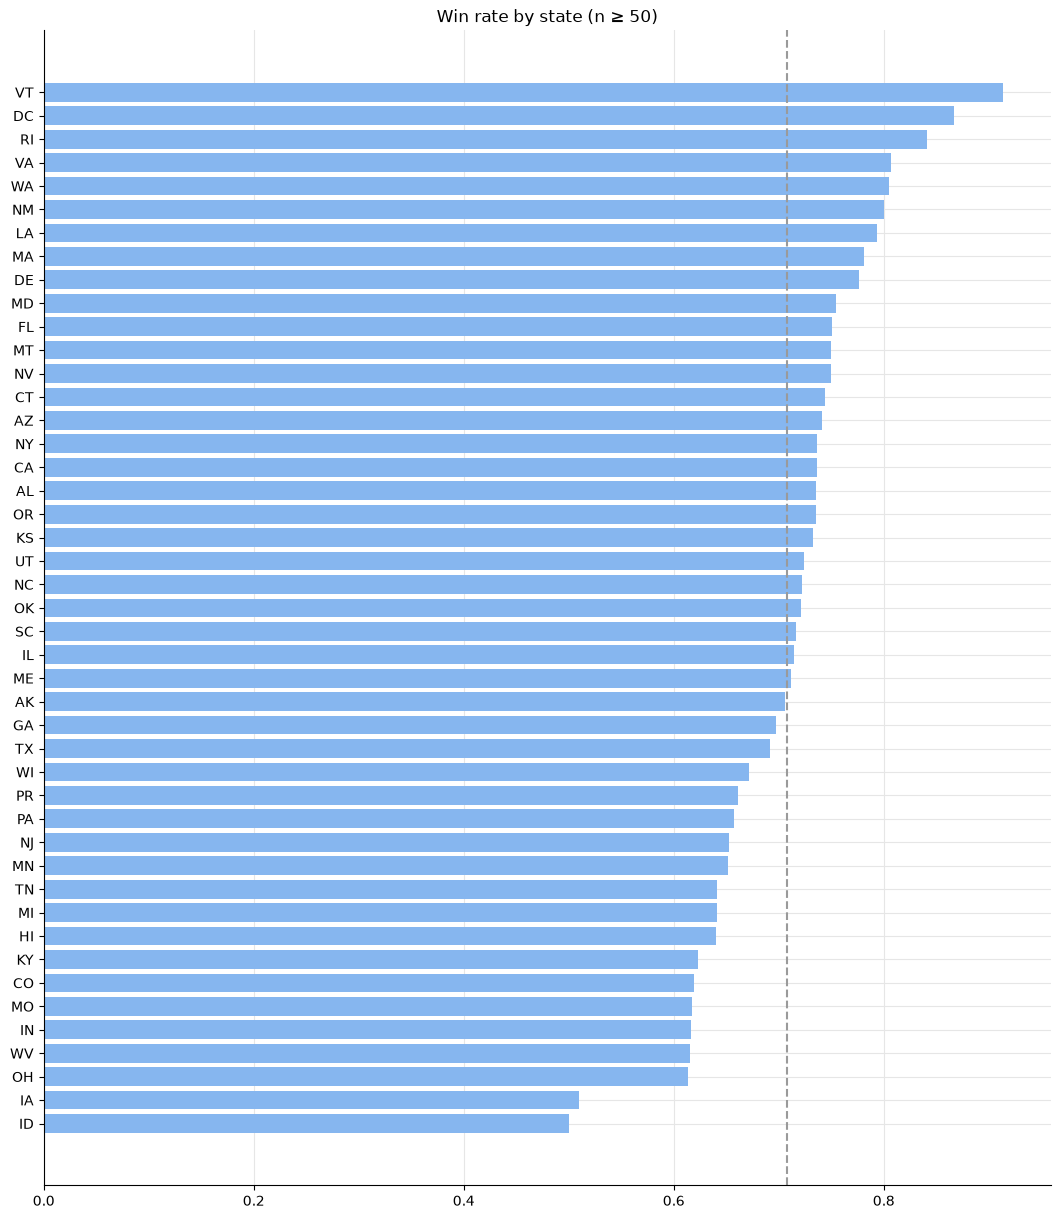

In [34]:
fig, ax1 = plt.subplots(1, 1, figsize=(13, 5))

reg = df.groupby('census_region')['union_won'].mean().sort_values()
ax1.barh(reg.index, reg.values, color=BLUE)
ax1.axvline(df['union_won'].mean(), color=GRAY, ls='--')
ax1.set_title('Win rate by region')
plt.show()
fig.savefig("../figures/sydney_eda/figure_2.png", dpi=300, bbox_inches="tight")

fig, ax2 = plt.subplots(1, 1, figsize=(13, 15))

st = df.groupby('state')['union_won'].agg(['mean', 'size'])
st = st[st['size'] >= 50].sort_values('mean')   # skip tiny states


ax2.barh(st.index, st['mean'], color=LIGHT_BLUE)
ax2.axvline(df['union_won'].mean(), color=GRAY, ls='--')
ax2.set_title('Win rate by state (n ≥ 50)')
plt.show()
fig.savefig("../figures/sydney_eda/figure_3.png", dpi=300, bbox_inches="tight")

## Exploration 4

Looking at the parent unions 

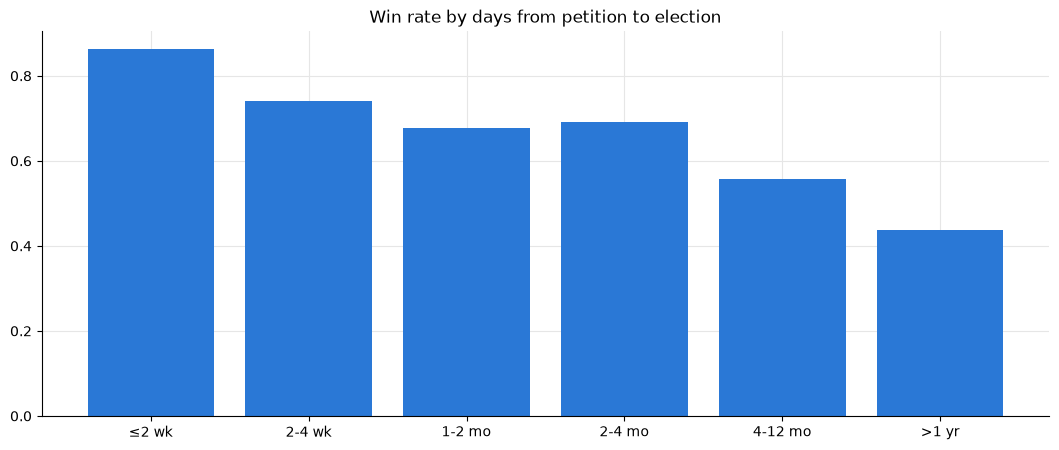

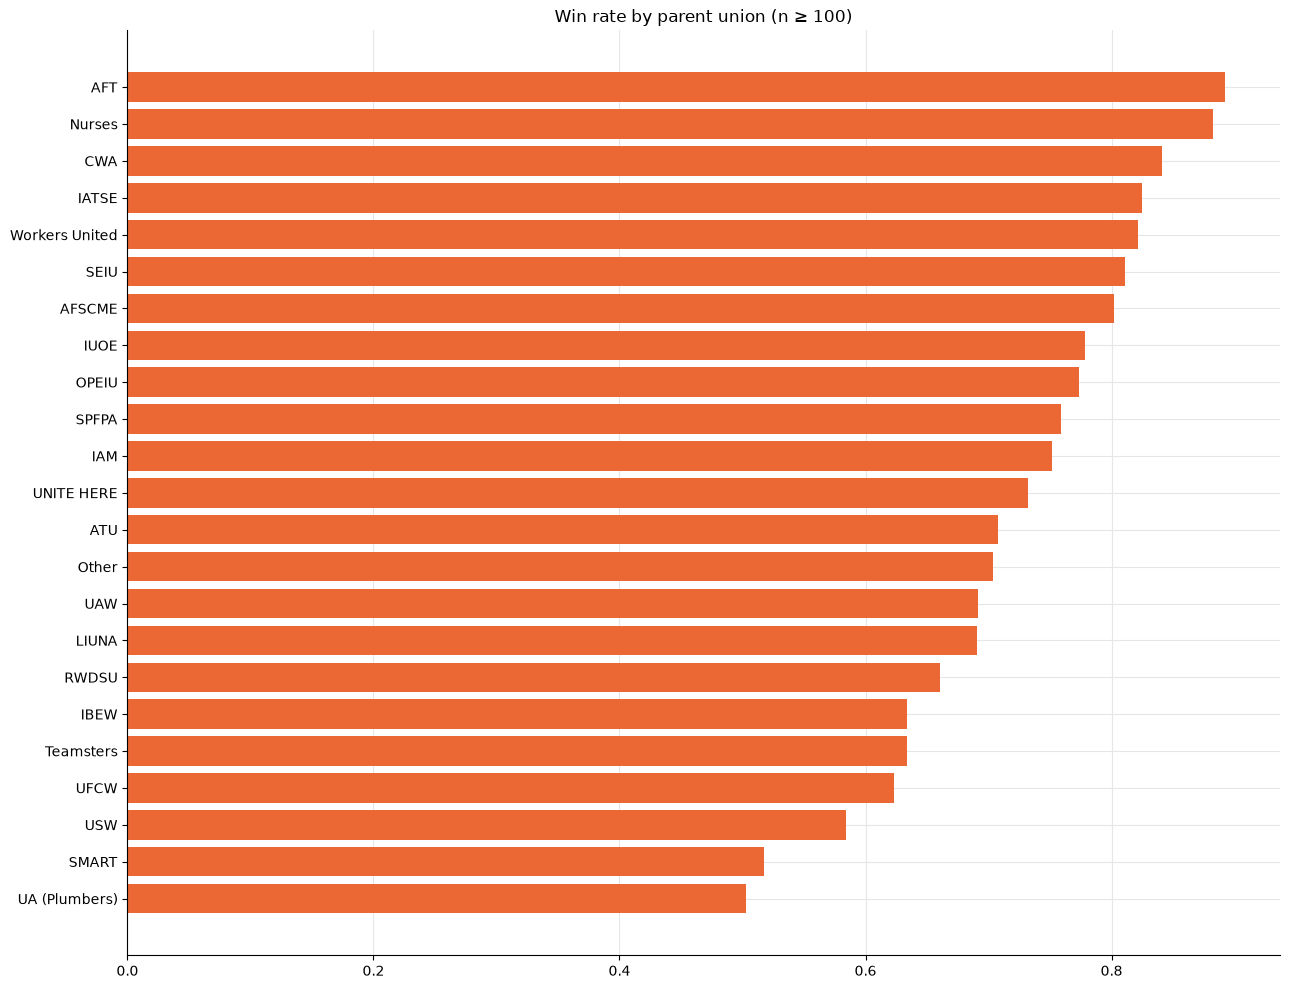

In [35]:
fig, ax1 = plt.subplots(1, 1, figsize=(13, 5))

bins = [0, 14, 30, 60, 120, 365, np.inf]
labels = ['≤2 wk', '2-4 wk', '1-2 mo', '2-4 mo', '4-12 mo', '>1 yr']
df['days_bin'] = pd.cut(df['days_petition_to_election'], bins=bins, labels=labels)
d = df.groupby('days_bin', observed=True)['union_won'].mean()
ax1.bar(d.index.astype(str), d.values, color=BLUE)
ax1.set_title('Win rate by days from petition to election')
plt.show()
fig.savefig("../figures/sydney_eda/figure_4.png", dpi=300, bbox_inches="tight")

fig, ax2 = plt.subplots(1, 1, figsize=(13, 10))
pu = df.groupby('parent_union')['union_won'].agg(['mean', 'size'])
pu = pu[pu['size'] >= 100].sort_values('mean')
ax2.barh(pu.index, pu['mean'], color=ORANGE)
ax2.set_title('Win rate by parent union (n ≥ 100)')
plt.tight_layout()
plt.show()
fig.savefig("../figures/sydney_eda/figure_5.png", dpi=300, bbox_inches="tight")


## Exploration 5

double checking numerical features with win/lose rate

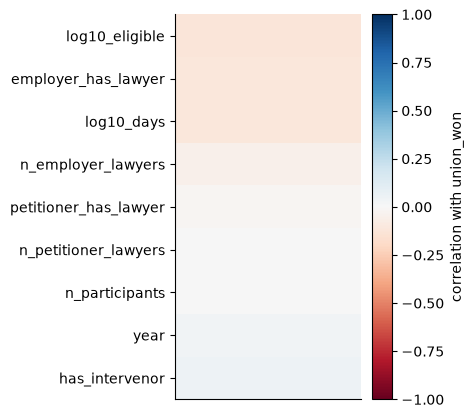

<Figure size 640x480 with 0 Axes>

In [36]:
target_corr = df[numeric_cols].corr()[['union_won']].drop('union_won').sort_values('union_won')

plt.figure(figsize=(3, 5))
plt.imshow(target_corr, cmap='RdBu', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(label='correlation with union_won')
plt.yticks(range(len(target_corr)), target_corr.index)
plt.xticks([])
plt.grid(False)
plt.show()
plt.savefig("../figures/sydney_eda/figure_6.png", dpi=300, bbox_inches="tight")